# Aligned FASTA with temperatures in the headers → FeatureDCA training inputs

This notebook takes an **aligned FASTA whose headers carry growth temperatures**, such as the output of
`filter_fasta_by_tempura.ipynb` run on an alignment:

`>sp|P09372|GRPE_ECOLI Protein GrpE OS=Escherichia coli (strain K12) OX=83333 GN=grpE PE=1 SV=1 Topt_ave=37`

and writes the two files that `analysis/train_jdomain_featuredca.jl` (TemperatureDCA repo) reads, in the same format as the
J-domain files in `data/processed_new/jdomain/`:

| file | content |
|---|---|
| `data/processed_new/<name>/<name>.aligned.maxgap50.fasta` | the cleaned alignment; headers `>seq000000001\|P09372\|tax83333 <original header>` |
| `data/processed_new/<name>/<name>.metadata.maxgap50.csv` | one row per FASTA record, same order: `sequence_id`, `accession`, `taxonomy_id`, `organism`, `gene`, the six TEMPURA temperature columns, `alignment_length`, `gap_fraction`, `description` |

**What the training script needs, and what the notebook does about it**

| `train_jdomain_featuredca.jl` ... | so this notebook ... |
|---|---|
| reads the alignment with `FeatureDCA.read_annotated_fasta` (DCAUtils): all records the same length; lower-case letters and `.` are skipped as insertions; `B J O U X Z *` are read as gaps | removes insertions (a2m/a3m), upper-cases, writes non-standard letters as `-`, and checks that every row has the same length |
| reads every record (`max_gap_fraction=1.0`), so gappy sequences have to be removed beforehand | drops sequences with more than `MAX_GAP_FRACTION` gaps (0.5, as `filter_aligned_dataset.py` does) |
| uses the first word of each header as the ID and needs it to be unique | gives every record a unique ID in the repo's style |
| looks every ID up in the metadata CSV (`sequence_id`) and needs a value for each `--features` column (default `Topt_ave`) | writes one metadata row per record and drops sequences without the selected temperatures |
| standardizes the features and stops if one of them is constant | checks that every feature varies |

`taxonomy_id` is also used downstream: the cross-validation scripts split train and test sets by organism with it.

At the end the notebook reads both files back, repeats these checks, and prints the `julia` command for training.

**Inputs:** the aligned FASTA. **Requirements:** `pandas`, `numpy`, `matplotlib`.

## 1. Setup

In [1]:
import re
import string
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 60)
pd.set_option("display.width", 160)

### Configuration
Set `FASTA_IN` and `REPO_ROOT`; the defaults of the other settings reproduce the J-domain dataset conventions.

In [11]:
# --- Input -------------------------------------------------------------------------------------
FASTA_IN = Path("../data/hrcA/uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned_tempura.fasta")   # aligned FASTA with Name=value temperature tags in the headers

# --- Output ------------------------------------------------------------------------------------
REPO_ROOT = Path(".")                   # TemperatureDCA checkout (the folder that contains analysis/ and data/)
DATASET_NAME = None                     # None = input name without "_tempura" (grpE_tempura.fasta -> grpE)
ID_STYLE = "pipeline"                   # "pipeline" = seq000000001|P09372|tax83333, as prepare_temperature_datasets.py
                                        # "original" = first word of the input header (must be unique)
OVERWRITE = False                       # False = stop instead of replacing existing output files

# --- Temperatures in the headers ---------------------------------------------------------------
# header tag -> metadata column; add aliases if your headers use other names, e.g. "Topt": "Topt_ave"
HEADER_TAGS = {c: c for c in ("Tmin", "Topt_ave", "Topt_low", "Topt_high", "Tmax", "Tmax_Tmin")}
FEATURES = ["Topt_ave"]                 # model features (passed to --features); sequences missing one are dropped

# --- Alignment cleaning ------------------------------------------------------------------------
LOWERCASE = "auto"                      # "insert" = lower case and '.' are insertions (a2m/a3m) and are removed
                                        # "residue" = lower case letters are residues and are upper-cased
                                        # "auto" = "insert" if the file mixes upper and lower case, else "residue"
NONSTANDARD = "gap"                     # B J O U X Z * : "gap" = write '-' (what FeatureDCA reads) | "drop" = drop sequence
MAX_COLUMN_GAP_FRACTION = None          # e.g. 0.9 = remove columns with > 90 % gaps first; None = keep every column
MAX_GAP_FRACTION = 0.5                  # drop sequences with > 50 % gaps (filter_aligned_dataset.py); None = keep all

# -----------------------------------------------------------------------------------------------
TEMPERATURE_COLUMNS = ["Tmin", "Topt_ave", "Topt_low", "Topt_high", "Tmax", "Tmax_Tmin"]  # accepted by the script
unknown = sorted(set(HEADER_TAGS.values()) - set(TEMPERATURE_COLUMNS))
assert not unknown, f"HEADER_TAGS maps to columns the training script doesn't know: {unknown}"
missing = sorted(set(FEATURES) - set(HEADER_TAGS.values()))
assert not missing, f"FEATURES not produced by any HEADER_TAGS entry: {missing}"
assert ID_STYLE in ("pipeline", "original") and LOWERCASE in ("auto", "insert", "residue")
assert NONSTANDARD in ("gap", "drop")

FASTA_IN, REPO_ROOT = Path(FASTA_IN), Path(REPO_ROOT)
name = DATASET_NAME or re.sub(r"_tempura$", "", FASTA_IN.stem)
suffix = "all" if MAX_GAP_FRACTION is None else f"maxgap{round(100 * MAX_GAP_FRACTION)}"
OUT_DIR = REPO_ROOT / "data" / "processed_new" / name
FASTA_OUT = OUT_DIR / f"{name}.aligned.{suffix}.fasta"
METADATA_OUT = OUT_DIR / f"{name}.metadata.{suffix}.csv"
MODEL_OUT = REPO_ROOT / "results" / "featuredca" / f"{name}_{'_'.join(f.lower() for f in FEATURES)}.jls"
TRAIN_SCRIPT = REPO_ROOT / "analysis" / "train_jdomain_featuredca.jl"

if not TRAIN_SCRIPT.exists():
    print(f"warning: {TRAIN_SCRIPT} not found - is REPO_ROOT the TemperatureDCA folder?")
print(f"input : {FASTA_IN}\noutput: {FASTA_OUT}\n        {METADATA_OUT}")

input : ..\data\hrcA\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned_tempura.fasta
output: data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.aligned.maxgap50.fasta
        data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.metadata.maxgap50.csv


## 2. Read the FASTA file
A record whose sequence spans several lines is joined into one string; nothing else is changed yet.

In [12]:
def read_fasta(path):
    # Return a list of (header without '>', sequence) in file order.
    records, header, chunks = [], None, []
    with open(path, encoding="utf-8-sig") as fh:
        for line in fh:
            line = line.rstrip("\r\n")
            if line.startswith(">"):
                if header is not None:
                    records.append((header, "".join(chunks)))
                header, chunks = line[1:].strip(), []
            elif header is not None:
                chunks.append("".join(line.split()))
            elif line.strip():
                raise ValueError(f"{path}: sequence data before the first '>' header")
    if header is not None:
        records.append((header, "".join(chunks)))
    return records


records = read_fasta(FASTA_IN)
assert records, f"{FASTA_IN} contains no FASTA records"
seqs = pd.DataFrame(records, columns=["header", "raw_sequence"])
seqs.index = pd.RangeIndex(1, len(seqs) + 1, name="input_index")   # position in the input file
seqs["status"] = "kept"                                             # becomes the reason when a record is dropped

lengths = seqs["raw_sequence"].str.len()
print(f"{len(seqs):,} records in {FASTA_IN}; row length {lengths.min()}-{lengths.max()}")
for h, s in records[:3]:
    print(f"  >{h}\n   {s[:70]}{'...' if len(s) > 70 else ''}")

3,840 records in ..\data\hrcA\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned_tempura.fasta; row length 217-217
  >tr|A0AB94IVK1|A0AB94IVK1_9BACT Multifunctional fusion protein OS=Fretibacterium fastidiosum OX=651822 GN=grpE PE=3 SV=1 Topt_ave=37
   EDLLNYVTNLLSRLTNCVAVAAVSGLDSMEIWHIDLMPLGGKNVLALIVLKGGLVHHTEFTLPCEVEPGL...
  >tr|A0A022KW50|A0A022KW50_9MICO Heat-inducible transcription repressor HrcA OS=Brachybacterium muris UCD-AY4 OX=1249481 GN=hrcA PE=3 SV=1 Topt_ave=31
   EELLLRTVRLLAQTTHQVAMVQYPARKQARIRHVELVKVADALLLVVLITESGRVDQRTVPLLAARDAAF...
  >tr|A0A060A240|A0A060A240_ACICK Heat-inducible transcription repressor HrcA OS=Acidithiobacillus caldus (strain ATCC 51756 / DSM 8584 / KU) OX=637389 GN=hrcA PE=3 SV=1 Topt_ave=45
   DEVLHAATEVLSQLTRMAGFVRVPRRATRILRHVDFLALREREVLAIFVTDRGDVENRLIRVEQALDQGQ...


## 3. Temperatures and organism from the headers

* **Temperatures**: every `Tag=value` with a tag from `HEADER_TAGS` (`Topt_ave=37`, `Tmin=15`, ...). If a tag occurs twice the
  last value is used. Values that aren't numbers count as missing.
* **Accession**: `sp|P09372|...` / `tr|...|...` (UniProtKB), `UniRef90_P09372`, or a `seq...|ACC|tax...` pipeline ID; otherwise
  the first word of the header without a `/start-end` range.
* **Organism**: `OS=` and `OX=` (UniProtKB) or `Tax=` and `TaxID=` (UniRef); `GN=` gives the gene.

Sequences without a value for every column in `FEATURES` are dropped.

In [13]:
TAG_RE = re.compile(r"(?<!\S)(" + "|".join(re.escape(t) for t in sorted(HEADER_TAGS, key=len, reverse=True))
                    + r")=(\S+)")
ACCESSION_RES = [re.compile(r"^seq\d+\|([^|\s]+)\|tax"),           # pipeline ID (prepare_temperature_datasets.py)
                 re.compile(r"(?<!\S)(?:sp|tr)\|([^|\s]+)\|"),      # UniProtKB
                 re.compile(r"(?<!\S)UniRef\d+_([^\s/|]+)")]        # UniRef
ORGANISM_RES = [re.compile(r"\bOS=(?P<organism>.+?)\s+OX=(?P<taxid>\d+)"),
                re.compile(r"\bTax=(?P<organism>.+?)\s+TaxID=(?P<taxid>\d+)")]
TAXID_RE = re.compile(r"\b(?:OX|TaxID)=(\d+)")
GENE_RE = re.compile(r"\bGN=(\S+)")
PAREN_RE = re.compile(r"\s*\([^)]*\)")


def accession_of(header):
    for regex in ACCESSION_RES:
        m = regex.search(header)
        if m:
            return m[1]
    return re.sub(r"/\d+-\d+$", "", header.split()[0])


def organism_of(header):
    # (taxid or None, organism name or '')
    for regex in ORGANISM_RES:
        m = regex.search(header)
        if m:
            return int(m["taxid"]), m["organism"].strip()
    m = TAXID_RE.search(header)
    return (int(m[1]) if m else None), ""


def normalize_species_name(name):
    # Same rule as prepare_temperature_datasets.py: 'Escherichia coli (strain K12)' -> 'escherichia coli'.
    name = PAREN_RE.sub("", name.strip().strip('"')).strip()
    parts = name.split()
    if len(parts) >= 3 and parts[0].lower() == "candidatus":
        return " ".join(parts[:3]).lower()
    if len(parts) >= 2 and parts[0].lower() not in {"uncultured", "environmental"}:
        return " ".join(parts[:2]).lower()
    return name.lower()


seqs["original_id"] = seqs["header"].str.split().str[0]
seqs["accession"] = seqs["header"].map(accession_of)
organisms = seqs["header"].map(organism_of)
seqs["taxonomy_id"] = pd.array([o[0] for o in organisms], dtype="Int64")
seqs["organism"] = [o[1] for o in organisms]
seqs["normalized_species"] = seqs["organism"].map(normalize_species_name)
seqs["gene"] = seqs["header"].map(lambda h: (m[1] if (m := GENE_RE.search(h)) else ""))

tags = seqs["header"].map(lambda h: {HEADER_TAGS[t]: v for t, v in TAG_RE.findall(h)})
for col in TEMPERATURE_COLUMNS:
    raw = tags.map(lambda d: d.get(col))
    seqs[col] = pd.to_numeric(raw, errors="coerce")
    bad = raw.notna() & seqs[col].isna()
    if bad.any():
        print(f"{col}: {bad.sum():,} values aren't numbers (e.g. {raw[bad].iloc[0]!r}) and count as missing")

found = pd.DataFrame({"records with a value": seqs[TEMPERATURE_COLUMNS].notna().sum()})
display(found[found["records with a value"] > 0])

no_feature = seqs[FEATURES].isna().any(axis=1)
seqs.loc[no_feature, "status"] = "no " + "/".join(FEATURES) + " in header"
print(f"{no_feature.sum():,} records lack {', '.join(FEATURES)} and are dropped; {(~no_feature).sum():,} remain")
if no_feature.any():
    display(seqs.loc[no_feature, ["header"]].head(5))
assert (~no_feature).any(), f"no header has {FEATURES} - check HEADER_TAGS against a header printed above"

kept = seqs["status"].eq("kept")
print(f"taxid found for {seqs.loc[kept, 'taxonomy_id'].notna().sum():,} / {kept.sum():,} remaining records; "
      f"{seqs.loc[kept, 'taxonomy_id'].nunique():,} organisms")
if seqs.loc[kept, "taxonomy_id"].isna().any():
    print("warning: records without a taxid can't be kept apart by organism in the cross-validation scripts")

# Same organism, different temperatures? (usually means the headers were made from different TEMPURA rows)
by_taxid = seqs[kept].dropna(subset=["taxonomy_id"]).groupby("taxonomy_id")[FEATURES].nunique()
conflicts = by_taxid[(by_taxid > 1).any(axis=1)]
if len(conflicts):
    print(f"warning: {len(conflicts):,} taxids have more than one value of {FEATURES}:")
    display(conflicts.head(10))

,records with a value
Topt_ave,3840


0 records lack Topt_ave and are dropped; 3,840 remain
taxid found for 3,840 / 3,840 remaining records; 3,716 organisms


## 4. Clean the alignment

`FeatureDCA.read_annotated_fasta` uses DCAUtils, which reads only upper-case letters and `-` as alignment columns
(lower case and `.` are skipped as insertions) and maps the 20 standard amino acids and the gap to 21 states;
`B J O U X Z *` become gaps. The notebook writes the alignment in that form directly:

* **Insertions** (`LOWERCASE`): in a2m (`hmmalign`, `jackhmmer`) and a3m files, lower-case letters and `.` are residues and gaps
  in insert states and are removed. If lower-case letters are ordinary residues (an all-lower-case file, or soft-masking)
  they are upper-cased instead; then `.` counts as a gap, and columns that are `.` in every sequence (insert columns whose
  residues belonged to sequences filtered out earlier) are removed.
* **Non-standard letters** (`NONSTANDARD`): written as `-`, or the sequence is dropped.
* Any other character stops the notebook, as does a file whose rows have different lengths after this step.

In [14]:
STANDARD = "ACDEFGHIKLMNPQRSTVWY"
NONSTANDARD_CHARS = "BJOUXZ*"
REMOVE_INSERTIONS = str.maketrans("", "", string.ascii_lowercase + ".")
GAP = ord("-")


def to_array(sequences):
    # equal-length ASCII strings -> (n_sequences, n_columns) uint8 array
    return np.frombuffer("".join(sequences).encode("ascii"), dtype=np.uint8).reshape(len(sequences), -1)


def to_strings(array):
    return [row.tobytes().decode("ascii") for row in array]


def clean_alignment(sequences, ids, lowercase="auto"):
    # Return (match-column sequences in upper case, without '.', the mode used, a log of what was changed).
    present = set("".join(sequences))
    mixed_case = any(c.islower() for c in present) and any(c.isupper() for c in present)
    mode = ("insert" if mixed_case else "residue") if lowercase == "auto" else lowercase
    log = {}
    if mode == "insert":
        out = [s.translate(REMOVE_INSERTIONS) for s in sequences]
        log["insert residues/gaps removed"] = sum(len(s) for s in sequences) - sum(len(s) for s in out)
    else:
        out = [s.upper() for s in sequences]

    unknown = set("".join(out)) - set(STANDARD + NONSTANDARD_CHARS + "-.")
    if unknown:
        example = next(i for i, s in zip(ids, out) if set(s) & unknown)
        raise ValueError(f"unexpected characters {sorted(unknown)} (e.g. in {example}); only amino-acid letters, "
                         "'-' and '.' are allowed")
    row_lengths = pd.Series([len(s) for s in out], index=ids)
    if row_lengths.nunique() > 1:
        raise ValueError(f"rows have {row_lengths.nunique()} different lengths after the '{mode}' rule (e.g. "
                         f"{row_lengths.idxmin()}: {row_lengths.min()}, {row_lengths.idxmax()}: {row_lengths.max()}). "
                         "Is the file aligned? Otherwise try the other LOWERCASE setting.")

    if mode == "residue" and "." in present:
        arr = to_array(out)
        dots = arr == ord(".")
        empty_insert_columns = dots.all(axis=0)
        log["columns that were '.' in every row, removed"] = int(empty_insert_columns.sum())
        arr = arr[:, ~empty_insert_columns]
        log["'.' written as '-'"] = int((arr == ord(".")).sum())
        arr[arr == ord(".")] = GAP
        out = to_strings(arr)
    return out, mode, log


kept = seqs["status"].eq("kept")
cleaned, mode, log = clean_alignment(seqs.loc[kept, "raw_sequence"].tolist(), seqs.loc[kept, "original_id"].tolist(),
                                     LOWERCASE)
seqs["sequence"] = pd.Series(cleaned, index=seqs.index[kept])
print(f"LOWERCASE rule used: '{mode}'; {len(cleaned[0])} alignment columns")
for what, n in log.items():
    print(f"  {what}: {n:,}")

# Non-standard letters
n_nonstd = seqs.loc[kept, "sequence"].map(lambda s: sum(s.count(c) for c in NONSTANDARD_CHARS))
print(f"non-standard letters ({' '.join(NONSTANDARD_CHARS)}): {n_nonstd.sum():,} in {(n_nonstd > 0).sum():,} sequences"
      + ("" if n_nonstd.sum() == 0 else " -> written as '-'" if NONSTANDARD == "gap" else " -> sequences dropped"))
if NONSTANDARD == "gap":
    to_gap = str.maketrans({c: "-" for c in NONSTANDARD_CHARS})
    seqs.loc[kept, "sequence"] = seqs.loc[kept, "sequence"].str.translate(to_gap)
else:
    seqs.loc[n_nonstd[n_nonstd > 0].index, "status"] = "non-standard letters"

LOWERCASE rule used: 'residue'; 217 alignment columns
non-standard letters (B J O U X Z *): 0 in 0 sequences


## 5. Gap filters

Columns first (optional, `MAX_COLUMN_GAP_FRACTION`), then sequences (`MAX_GAP_FRACTION`). The repo's J-domain dataset keeps
all 62 HMM match columns and drops sequences with more than 50 % gaps. For a wide alignment that wasn't trimmed to a
profile (e.g. MAFFT of full-length proteins) many columns can be almost empty; they make training slower without adding
much, and the column summary below shows whether that's the case.

217 columns; gap fraction per column: median 0.00, 0 columns > 50 % gaps, 0 > 90 %, 0 only gaps
MAX_GAP_FRACTION = 0.5: dropped 8 of 3,840 sequences

3,832 sequences x 217 columns from 3,713 organisms


,records
status,
kept,3832
gap fraction > 0.5,8


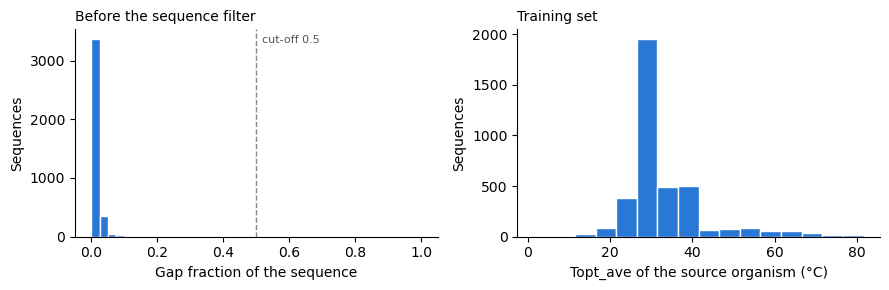

In [15]:
kept = seqs["status"].eq("kept")
arr = to_array(seqs.loc[kept, "sequence"].tolist())
column_gaps = (arr == GAP).mean(axis=0)
print(f"{arr.shape[1]} columns; gap fraction per column: median {np.median(column_gaps):.2f}, "
      f"{(column_gaps > 0.5).sum()} columns > 50 % gaps, {(column_gaps > 0.9).sum()} > 90 %, "
      f"{(column_gaps == 1).sum()} only gaps")
if MAX_COLUMN_GAP_FRACTION is not None:
    keep_columns = column_gaps <= MAX_COLUMN_GAP_FRACTION
    arr = arr[:, keep_columns]
    seqs.loc[kept, "sequence"] = to_strings(arr)
    print(f"MAX_COLUMN_GAP_FRACTION = {MAX_COLUMN_GAP_FRACTION}: removed {(~keep_columns).sum()} columns, "
          f"{arr.shape[1]} left")
    assert arr.shape[1] > 0, "every column was removed"

seqs["gap_fraction"] = pd.Series((arr == GAP).mean(axis=1), index=seqs.index[kept])
gap_values = seqs.loc[kept, "gap_fraction"]
if MAX_GAP_FRACTION is not None:
    too_gappy = kept & (seqs["gap_fraction"] > MAX_GAP_FRACTION)
    seqs.loc[too_gappy, "status"] = f"gap fraction > {MAX_GAP_FRACTION}"
    print(f"MAX_GAP_FRACTION = {MAX_GAP_FRACTION}: dropped {too_gappy.sum():,} of {kept.sum():,} sequences")

final = seqs[seqs["status"].eq("kept")].copy()
assert len(final), "no sequence is left - relax the filters"
constant = [f for f in FEATURES if final[f].nunique() < 2]
assert not constant, f"{constant} has the same value for every sequence; the training script can't standardize it"
print(f"\n{len(final):,} sequences x {len(final['sequence'].iloc[0])} columns from "
      f"{final['taxonomy_id'].nunique():,} organisms")
display(seqs["status"].value_counts().rename("records").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
ax = axes[0]
ax.hist(gap_values, bins=np.linspace(0, 1, 41), color="#2a78d6", edgecolor="white", linewidth=1)
if MAX_GAP_FRACTION is not None:
    ax.axvline(MAX_GAP_FRACTION, color="#898781", lw=1, ls="--")
    ax.annotate(f"cut-off {MAX_GAP_FRACTION}", (MAX_GAP_FRACTION, 1), xycoords=("data", "axes fraction"),
                xytext=(4, -4), textcoords="offset points", va="top", fontsize=8, color="#55534e")
ax.set_xlabel("Gap fraction of the sequence")
ax.set_ylabel("Sequences")
ax.set_title("Before the sequence filter", fontsize=10, loc="left")
ax = axes[1]
feature = FEATURES[0]
lo, hi = np.floor(final[feature].min()), np.ceil(final[feature].max())
ax.hist(final[feature], bins=np.arange(lo - 2.5, hi + 5, 5) if hi - lo > 10 else 20, color="#2a78d6",
        edgecolor="white", linewidth=1)
ax.set_xlabel(f"{feature} of the source organism (°C)")
ax.set_ylabel("Sequences")
ax.set_title("Training set", fontsize=10, loc="left")
for ax in axes:
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
fig.tight_layout()
plt.show()

## 6. Write the FASTA file and the metadata CSV

With `ID_STYLE = "pipeline"` each record gets the ID `seq<input position>|<accession>|tax<taxid>`, the convention of
`prepare_temperature_datasets.py`, followed by the original header; the original first word is kept in `original_id`.
Both files list the sequences in the same order (input order). Temperatures that aren't in the headers are left empty;
the training script only needs the columns passed to `--features`.

In [16]:
if ID_STYLE == "pipeline":
    final["sequence_id"] = [f"seq{i:09d}|{acc}|tax{tax if pd.notna(tax) else 'NA'}"
                            for i, acc, tax in zip(final.index, final["accession"], final["taxonomy_id"])]
    final["fasta_header"] = final["sequence_id"] + " " + final["header"]
else:
    final["sequence_id"] = final["original_id"]
    final["fasta_header"] = final["header"]
duplicated = final["sequence_id"][final["sequence_id"].duplicated(keep=False)]
assert duplicated.empty, (f"{duplicated.nunique():,} IDs occur more than once (e.g. {duplicated.iloc[0]}); "
                          "use ID_STYLE = 'pipeline'")

final["alignment_length"] = final["sequence"].str.len()
final["description"] = final["header"]
metadata_columns = ["sequence_id", "original_id", "accession", "taxonomy_id", "organism", "normalized_species", "gene",
                    *TEMPERATURE_COLUMNS, "alignment_length", "gap_fraction", "description"]
metadata = final[metadata_columns].copy()
metadata["gap_fraction"] = metadata["gap_fraction"].map(lambda x: f"{x:.6f}")

existing = [p for p in (FASTA_OUT, METADATA_OUT) if p.exists()]
if existing and not OVERWRITE:
    raise FileExistsError(f"{', '.join(map(str, existing))} already exist; set OVERWRITE = True to replace them")
OUT_DIR.mkdir(parents=True, exist_ok=True)
with open(FASTA_OUT, "w", encoding="utf-8", newline="\n") as fh:
    for header, sequence in zip(final["fasta_header"], final["sequence"]):
        fh.write(f">{header}\n{sequence}\n")
metadata.to_csv(METADATA_OUT, index=False, lineterminator="\n")
print(f"Saved {FASTA_OUT} and {METADATA_OUT} ({len(final):,} sequences)")
display(metadata.head(3))

Saved data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.aligned.maxgap50.fasta and data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.metadata.maxgap50.csv (3,832 sequences)


,sequence_id,original_id,accession,taxonomy_id,organism,normalized_species,gene,Tmin,Topt_ave,Topt_low,Topt_high,Tmax,Tmax_Tmin,alignment_length,gap_fraction,description
input_index,,,,,,,,,,,,,,,,
1,seq000000001|A0AB94IVK1|tax651822,tr|A0AB94IVK1|A0AB94IVK1_9BACT,A0AB94IVK1,651822,Fretibacterium fastidiosum,fretibacterium fastidiosum,grpE,NaN,37.0,NaN,NaN,NaN,NaN,217,0.009217,tr|A0AB94IVK1|A0AB94IVK1_9BACT Multifunctional...
2,seq000000002|A0A022KW50|tax1249481,tr|A0A022KW50|A0A022KW50_9MICO,A0A022KW50,1249481,Brachybacterium muris UCD-AY4,brachybacterium muris,hrcA,NaN,31.0,NaN,NaN,NaN,NaN,217,0.046083,tr|A0A022KW50|A0A022KW50_9MICO Heat-inducible ...
3,seq000000003|A0A060A240|tax637389,tr|A0A060A240|A0A060A240_ACICK,A0A060A240,637389,Acidithiobacillus caldus (strain ATCC 51756 / ...,acidithiobacillus caldus,hrcA,NaN,45.0,NaN,NaN,NaN,NaN,217,0.004608,tr|A0A060A240|A0A060A240_ACICK Heat-inducible ...


## 7. Check the files the way the training script reads them

Both files are read back from disk and checked against what `train_jdomain_featuredca.jl` and
`FeatureDCA.read_annotated_fasta` require. If this cell passes, the Julia script's `--dry-run` should too.

In [17]:
import csv


def check_featuredca_inputs(fasta_path, metadata_path, features):
    records = read_fasta(fasta_path)
    ids = [h.split()[0] for h, _ in records]
    sequences = [s for _, s in records]

    # FeatureDCA.read_annotated_fasta / DCAUtils.read_fasta_alignment
    assert records, "the FASTA file is empty"
    assert len({len(s) for s in sequences}) == 1, "rows have different lengths"
    allowed = set(STANDARD + "-")
    bad = [i for i, s in zip(ids, sequences) if not set(s) <= allowed]
    assert not bad, f"{len(bad)} rows contain characters other than the 20 amino acids and '-' (e.g. {bad[0]})"
    assert len(set(ids)) == len(ids), "FASTA contains duplicate sequence IDs"

    # train_jdomain_featuredca.jl: read_metadata
    with open(metadata_path, newline="", encoding="utf-8") as fh:
        rows = list(csv.reader(fh))
    header, rows = rows[0], rows[1:]
    assert len(set(header)) == len(header), "metadata has duplicate column names"
    assert all(len(r) == len(header) for r in rows), "malformed metadata row"
    meta = pd.DataFrame(rows, columns=header)
    assert meta["sequence_id"].is_unique, "duplicate metadata sequence_id"
    missing = set(ids) - set(meta["sequence_id"])
    assert not missing, f"{len(missing)} FASTA records lack metadata"
    meta = meta.set_index("sequence_id").loc[ids]

    # features: complete, numeric, not constant (the script standardizes them)
    for f in features:
        assert f in meta.columns, f"metadata has no {f} column"
        values = pd.to_numeric(meta[f].str.strip(), errors="coerce")
        assert values.notna().all(), f"{values.isna().sum()} records have an empty or non-numeric {f}"
        assert values.nunique() > 1, f"{f} has the same value for every sequence"

    if not any("-" in s for s in sequences):
        print("note: the alignment has no gaps, so FeatureDCA will use q = 20 instead of 21")
    L = len(sequences[0])
    print(f"OK: {len(records):,} sequences x {L} columns, IDs unique and all in the metadata, "
          f"features {', '.join(features)} complete")
    return meta


checked = check_featuredca_inputs(FASTA_OUT, METADATA_OUT, FEATURES)
summary = pd.DataFrame({f: pd.to_numeric(checked[f]).describe()[["mean", "std", "min", "max"]] for f in FEATURES}).T
display(summary.round(2))
print(f"{checked['taxonomy_id'].replace('', np.nan).nunique():,} organisms, "
      f"{len(checked) / max(checked['taxonomy_id'].replace('', np.nan).nunique(), 1):.1f} sequences per organism")

OK: 3,832 sequences x 217 columns, IDs unique and all in the metadata, features Topt_ave complete


,mean,std,min,max
Topt_ave,32.86,9.7,4.0,80.0


3,713 organisms, 1.0 sequences per organism


## 8. Train

Run from the TemperatureDCA folder. `--output` matters: without it the model is written to
`results/featuredca/jdomain_topt_ave.jls` and replaces the J-domain model. Start with `--dry-run`, which only reads the
files and builds the inputs.

In [18]:
def repo_path(p):
    return p.relative_to(REPO_ROOT) if p.is_relative_to(REPO_ROOT) else p.resolve()


command = ("JULIA_NUM_THREADS=auto julia --project=. analysis/train_jdomain_featuredca.jl \\\n"
           f"  --fasta {repo_path(FASTA_OUT)} \\\n"
           f"  --metadata {repo_path(METADATA_OUT)} \\\n"
           f"  --features {','.join(FEATURES)} \\\n"
           f"  --output {repo_path(MODEL_OUT)}")
print("# check (no training)\n" + command + " \\\n  --dry-run\n")
print("# train\n" + command)
if MODEL_OUT.exists():
    print(f"\nwarning: {MODEL_OUT} already exists and training will replace it; choose another --output to keep it")

# check (no training)
JULIA_NUM_THREADS=auto julia --project=. analysis/train_jdomain_featuredca.jl \
  --fasta data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.aligned.maxgap50.fasta \
  --metadata data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.metadata.maxgap50.csv \
  --features Topt_ave \
  --output results\featuredca\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned_topt_ave.jls \
  --dry-run

# train
JULIA_NUM_THREADS=auto julia --project=. analysis/train_jdomain_featuredca.jl \
  --fasta data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.aligned.maxgap50.fasta \
  --metadata data\processed_new\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned\uniprotkb_xref_pfam_PF01628_AND_keyword_2026_10_13_aligned.m

## Make fake metadata

In [2]:
import pandas as pd
metadata=pd.read_csv("./data/processed_new/uniprotkb_xref_pfam_PF01025_AND_keyword_2026_10_12_aligned/uniprotkb_xref_pfam_PF01025_AND_keyword_2026_10_12_aligned.metadata.maxgap50.csv")

# only keep tempura_match_mode and gene columns:
metadata = metadata[["sequence_id", "accession","taxonomy_id","organism","Topt_ave","gap_fraction"]]

# put all elements in Topt_ave column to 30:
metadata["Topt_ave"] = 30
metadata.to_csv("./data/processed_new/uniprotkb_xref_pfam_PF01025_AND_keyword_2026_10_12_aligned/PF01025_metadata_fake.csv", index=False)